# Chapitre 18 - Exercices 18.16 à 18.20 : tests multiples

Ces cinq exercices portent sur la section 18.7 du livre (évaluation de l'importance de
chaque variable et problème des **tests multiples**) :

- **18.16** : la méthode de Bonferroni contrôle le taux d'erreur par famille (FWER) ;
- **18.17** : équivalence entre la procédure de Benjamini–Hochberg et l'estimation
  « plug-in » du taux de fausses découvertes (FDR) ;
- **18.18** : expression bayésienne du pFDR à l'aide de l'erreur de type I et de la
  puissance ;
- **18.19** : étude complète (FDR plug-in, BH, estimation de $\pi_0$) sur des données de
  micro-puces ;
- **18.20** : démonstration du résultat (18.53), $\text{pFDR}(\Gamma) = \Pr(Z = 0 \mid t \in \Gamma)$.

Les fonctions utilisées sont dans `esl/ch18_grande_dimension_complements.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch18_grande_dimension_complements as g18
set_style()

### Rappels communs : vocabulaire des tests multiples

On teste $M$ hypothèses nulles $H_{01}, \dots, H_{0M}$ (par exemple « le gène $j$ a la
même expression moyenne dans les deux groupes »). Chaque test fournit une **p-valeur**
$p_j$. Sous $H_{0j}$, $p_j$ suit (au moins approximativement) la loi uniforme sur
$[0, 1]$, de sorte que $\Pr(p_j < u) = u$ : rejeter quand $p_j < u$ donne une erreur de
type I égale à $u$.

Le tableau 18.5 du livre résume les issues possibles :

| | non rejetée | rejetée | total |
|---|---|---|---|
| $H_0$ vraie | $U$ | $V$ | $M_0$ |
| $H_0$ fausse | $T$ | $S$ | $M_1$ |
| total | $M - R$ | $R$ | $M$ |

$V$ est le nombre de **faux positifs** et $R$ le nombre total de rejets.

- **FWER** (taux d'erreur par famille) : $\Pr(V \ge 1)$.
- **FDR** (taux de fausses découvertes, éq. (18.43)) : $E(V/R)$, avec la convention
  $V/R = 0$ si $R = 0$.
- **pFDR** (FDR positif, éq. (18.50)) : $E(V/R \mid R > 0)$.

## Exercice 18.16 : Méthode de Bonferroni

**Énoncé (reformulé).** On teste $M$ hypothèses nulles $H_{0j}$ de p-valeurs $p_j$. Soit
$A$ l'événement « au moins une hypothèse nulle est rejetée à tort » et $A_j$ l'événement
« la $j$-ème hypothèse nulle est rejetée à tort ». La méthode de Bonferroni rejette
$H_{0j}$ si $p_j < \alpha/M$.

(a) Montrer que $\Pr(A) \le \alpha$. *Indication :*
$\Pr(A_j \cup A_{j'}) = \Pr(A_j) + \Pr(A_{j'}) - \Pr(A_j \cap A_{j'})$.

(b) Si les hypothèses sont indépendantes,
$\Pr(A) = 1 - \Pr(A^c) = 1 - \prod_j \Pr(A_j^c) = 1 - (1 - \alpha/M)^M$. En déduire que
$\Pr(A) \approx \alpha$ dans ce cas.

### (a) Inégalité de la réunion

**Étape 1 : deux événements.** D'après l'indication, et puisqu'une probabilité est
positive,
$\Pr(A_j \cup A_{j'}) = \Pr(A_j) + \Pr(A_{j'}) - \Pr(A_j \cap A_{j'}) \le \Pr(A_j) + \Pr(A_{j'})$.

**Étape 2 : récurrence.** Supposons $\Pr\big(\bigcup_{j=1}^{m} A_j\big) \le \sum_{j=1}^m \Pr(A_j)$.
En appliquant l'étape 1 aux deux événements $B = \bigcup_{j=1}^{m} A_j$ et $A_{m+1}$ :

$$
\Pr\Big(\bigcup_{j=1}^{m+1} A_j\Big) \le \Pr(B) + \Pr(A_{m+1}) \le \sum_{j=1}^{m+1} \Pr(A_j).
$$

C'est l'**inégalité de Boole** : $\Pr\big(\bigcup_j A_j\big) \le \sum_j \Pr(A_j)$.

**Étape 3 : probabilité de chaque fausse alarme.** Si $H_{0j}$ est fausse, l'événement
$A_j$ est impossible (on ne peut pas la rejeter *à tort*) : $\Pr(A_j) = 0$. Si $H_{0j}$ est
vraie, $p_j$ est uniforme et $\Pr(A_j) = \Pr(p_j < \alpha/M) = \alpha/M$.

**Conclusion.** Avec $M_0 \le M$ hypothèses nulles vraies,

$$
\Pr(A) = \Pr\Big(\bigcup_{j=1}^M A_j\Big) \le \sum_{j=1}^M \Pr(A_j) = M_0\,\frac{\alpha}{M} \le \alpha .
$$

Aucune hypothèse d'indépendance n'a été utilisée : la garantie est valable quelle que
soit la dépendance entre les tests.

### (b) Cas indépendant : la borne est presque atteinte

On suppose ici toutes les hypothèses nulles vraies et les tests indépendants, de sorte
que $\Pr(A) = 1 - (1 - \alpha/M)^M$. Encadrons cette quantité.

- **Majoration** (inégalité de Bernoulli $(1 - x)^M \ge 1 - Mx$ pour $0 \le x \le 1$) :
  $(1 - \alpha/M)^M \ge 1 - \alpha$, donc $\Pr(A) \le \alpha$ (on retrouve (a)).
- **Minoration** : $\log(1 - x) \le -x$ (concavité du logarithme), donc
  $(1 - \alpha/M)^M = e^{M\log(1 - \alpha/M)} \le e^{-\alpha}$, et
  $\Pr(A) \ge 1 - e^{-\alpha}$.
- Enfin $e^{-\alpha} \le 1 - \alpha + \alpha^2/2$ pour $\alpha \ge 0$ : la fonction
  $g(\alpha) = e^{-\alpha} - 1 + \alpha - \alpha^2/2$ vérifie $g(0) = 0$ et
  $g'(\alpha) = 1 - \alpha - e^{-\alpha} \le 0$ (car $e^{-\alpha} \ge 1 - \alpha$, inégalité de
  convexité), donc $g \le 0$ sur $[0, +\infty[$.

On obtient l'encadrement, valable pour tout $M$ :

$$
\alpha - \frac{\alpha^2}{2} \;\le\; 1 - e^{-\alpha} \;\le\; \Pr(A) \;\le\; \alpha .
$$

L'erreur relative est au plus $\alpha/2$ : pour $\alpha = 0{,}05$,
$0{,}0488 \le \Pr(A) \le 0{,}05$. Donc $\Pr(A) \approx \alpha$. De plus
$(1 - \alpha/M)^M \to e^{-\alpha}$ quand $M \to \infty$.

In [2]:
alpha = 0.05
Ms = np.unique(np.logspace(0, 4, 50).astype(int))
fwer_exact = 1 - (1 - alpha / Ms) ** Ms
print("M = 1 : %.4f   M = 10 : %.4f   M = 10000 : %.4f   1 - exp(-alpha) = %.4f"
      % (fwer_exact[0], 1 - (1 - alpha / 10) ** 10, fwer_exact[-1], 1 - np.exp(-alpha)))

M = 1 : 0.0500   M = 10 : 0.0489   M = 10000 : 0.0488   1 - exp(-alpha) = 0.0488


### Simulation : tests indépendants ou corrélés

On simule $M$ statistiques $z_j$ gaussiennes sous $H_0$, de corrélation commune $\rho$
($z_j = \sqrt\rho\,W + \sqrt{1 - \rho}\,E_j$), et des tests bilatéraux. On estime le
FWER de Bonferroni sur 4000 répétitions.

In [3]:
rng = np.random.RandomState(0)
n_rep = 4000
res = {}
for rho in [0.0, 0.5, 0.9]:
    fw = []
    for M in [1, 10, 100, 1000]:
        z = np.sqrt(rho) * rng.randn(n_rep, 1) + np.sqrt(1 - rho) * rng.randn(n_rep, M)
        pv = 2 * stats.norm.sf(np.abs(z))
        fw.append(np.mean(np.any(pv < alpha / M, axis=1)))
    res[rho] = fw
    print("rho = %.1f :" % rho, np.round(fw, 4))

rho = 0.0 : [0.051  0.052  0.0442 0.041 ]


rho = 0.5 : [0.0498 0.0422 0.0332 0.022 ]


rho = 0.9 : [0.052  0.0165 0.0068 0.0012]


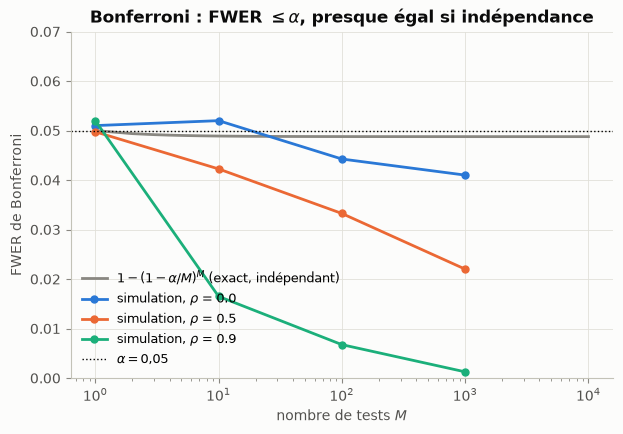

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(Ms, fwer_exact, color=GRAY, label=r"$1-(1-\alpha/M)^M$ (exact, indépendant)")
for c, rho in zip(COLORS, [0.0, 0.5, 0.9]):
    ax.semilogx([1, 10, 100, 1000], res[rho], "o-", color=c,
                label=r"simulation, $\rho$ = %.1f" % rho)
ax.axhline(alpha, color="k", lw=1, ls=":", label=r"$\alpha = 0{,}05$")
ax.set_xlabel("nombre de tests $M$")
ax.set_ylabel("FWER de Bonferroni")
ax.set_ylim(0, 0.07)
ax.set_title("Bonferroni : FWER $\\leq \\alpha$, presque égal si indépendance")
ax.legend(loc="lower left")
plt.show()

Sans corrélation, le FWER colle à $\alpha$ ; avec une forte corrélation positive, les
fausses alarmes ont tendance à arriver ensemble, le FWER est bien inférieur à $\alpha$ :
Bonferroni devient **conservatrice** (elle rejette trop peu).

> **À retenir.** Par l'inégalité de Boole, rejeter quand $p_j < \alpha/M$ garantit
> $\text{FWER} \le \alpha$ sans aucune hypothèse de dépendance ; en cas d'indépendance le
> FWER vaut $1 - (1 - \alpha/M)^M \in [1 - e^{-\alpha}, \alpha]$.

## Exercice 18.17 : Benjamini–Hochberg et FDR plug-in sont équivalents

**Énoncé (reformulé).** Avec les notations de l'algorithme 18.2 :

(a) montrer que, pour le seuil de rejet $p_0 = p_{(L)}$, une proportion d'au plus $p_0$
des statistiques permutées $t_{kj}$ dépasse $|T|_{(L)}$, la $L$-ième plus grande valeur
des $|t_j|$. En déduire que l'estimation plug-in $\widehat{\text{FDR}}$ est inférieure
ou égale à $p_0 \cdot M/L = \alpha$ ;

(b) montrer que le seuil $|T|_{(L+1)}$ donne un test dont le FDR estimé est supérieur
à $\alpha$.

### Rappels : les objets en jeu

- **Statistiques observées** $t_j$, $j = 1, \dots, M$ (t-statistiques (18.38)), et
  **statistiques permutées** $t_{kj}$, $k = 1, \dots, K$, recalculées après $K$
  permutations aléatoires des étiquettes de groupe (elles simulent l'hypothèse nulle).
- **p-valeurs mutualisées** (éq. (18.41)) : la proportion de toutes les $MK$ valeurs
  permutées qui dépassent $|t_j|$ :
  $$p_j = \frac{1}{MK}\sum_{j'=1}^M\sum_{k=1}^K I(|t_{kj'}| \ge |t_j|).$$
- **BH (algorithme 18.2)** : on ordonne $p_{(1)} \le \dots \le p_{(M)}$, on pose
  $L = \max\{j : p_{(j)} < \alpha j/M\}$ (éq. (18.44)) et on rejette les $H_{0j}$ telles
  que $p_j \le p_{(L)}$.
- **Plug-in (algorithme 18.3)** : pour un seuil $C$,
  $R_{\text{obs}}(C) = \#\{j : |t_j| \ge C\}$,
  $\widehat{E(V)}(C) = \frac1K\#\{(j, k) : |t_{kj}| \ge C\}$ (nombre moyen de rejets
  par jeu permuté, donc sous $H_0$), et $\widehat{\text{FDR}}(C) = \widehat{E(V)}(C)/R_{\text{obs}}(C)$.

Nous utilisons partout la convention « $\ge$ » (le livre mélange $>$ et $\ge$, ce qui
ne change rien en l'absence d'ex aequo) et supposons les $|t_j|$ deux à deux distincts.

### Lemme : le FDR plug-in au seuil $|T|_{(l)}$

La p-valeur $p_j$ est une fonction **décroissante** de $|t_j|$ : plus la statistique
est grande, moins il y a de valeurs permutées au-dessus. Donc la $l$-ième plus petite
p-valeur correspond à la $l$-ième plus grande statistique : $p_{(l)}$ est la p-valeur du
gène de statistique $|T|_{(l)}$, et

$$
p_{(l)} = \frac{1}{MK}\#\{(j, k) : |t_{kj}| \ge |T|_{(l)}\}
\quad\Longrightarrow\quad
\widehat{E(V)}\big(|T|_{(l)}\big) = \frac1K\#\{(j,k) : |t_{kj}| \ge |T|_{(l)}\} = M\,p_{(l)} .
$$

Par ailleurs exactement $l$ statistiques observées sont $\ge |T|_{(l)}$ :
$R_{\text{obs}}(|T|_{(l)}) = l$. D'où l'identité clé

$$
\widehat{\text{FDR}}\big(|T|_{(l)}\big) = \frac{M\,p_{(l)}}{l}, \qquad l = 1, \dots, M .
$$

### (a) Le seuil de BH a un FDR estimé inférieur à $\alpha$

Pour $l = L$ : la proportion des $MK$ valeurs permutées qui dépassent $|T|_{(L)}$ est
exactement $p_{(L)} = p_0$ (« au plus $p_0$ » avec l'inégalité stricte du livre). Le
lemme donne

$$
\widehat{\text{FDR}}\big(|T|_{(L)}\big) = \frac{M\,p_0}{L} < \frac{M}{L}\cdot\frac{\alpha L}{M} = \alpha ,
$$

où l'on a utilisé la définition de $L$ : $p_{(L)} < \alpha L/M$. (Le livre écrit
$p_0M/L = \alpha$ en assimilant $p_{(L)}$ à la droite $\alpha L/M$ : en réalité on a une
inégalité.) De plus, rejeter les $p_j \le p_{(L)}$ (BH) revient à rejeter les
$|t_j| \ge |T|_{(L)}$ (plug-in au seuil $C = |T|_{(L)}$) : ce sont les mêmes $L$ gènes.

### (b) Un seuil plus bas fait dépasser $\alpha$

Par maximalité de $L$, l'indice $L + 1$ ne vérifie pas la condition (18.44) :
$p_{(L+1)} \ge \alpha(L+1)/M$. Le lemme pour $l = L + 1$ donne

$$
\widehat{\text{FDR}}\big(|T|_{(L+1)}\big) = \frac{M\,p_{(L+1)}}{L + 1} \ge \alpha .
$$

Plus généralement, pour tout $l > L$, $\widehat{\text{FDR}}(|T|_{(l)}) \ge \alpha$. Donc
$|T|_{(L)}$ est **le plus petit seuil observé dont le FDR plug-in est inférieur à
$\alpha$** : la procédure « baisser le seuil tant que $\widehat{\text{FDR}} < \alpha$ »
rejette exactement les mêmes hypothèses que BH.

### Vérification numérique

Sur des données simulées ($M = 2000$ gènes, 20 + 20 échantillons, 100 gènes
réellement différentiels, $K = 200$ permutations), on compare les ensembles rejetés
par BH et par la règle plug-in pour plusieurs $\alpha$, et on vérifie l'identité
$\widehat{\text{FDR}}(|T|_{(l)}) = Mp_{(l)}/l$.

In [5]:
rng = np.random.RandomState(0)
M, n1, n2 = 2000, 20, 20
Xs = rng.randn(M, n1 + n2)
grp = np.r_[np.zeros(n1, bool), np.ones(n2, bool)]
Xs[:100, grp] += 1.2
ts = g18.two_sample_t(Xs, grp)
tps = g18.permutation_t(Xs, grp, 200, rng)
ps = g18.pooled_pvalues(ts, tps)
for a in [0.01, 0.05, 0.1, 0.2]:
    L, rej_bh = g18.benjamini_hochberg(ps, a)
    rej_pi = g18.plugin_reject(ts, tps, a)
    print("alpha = %.2f : L = %3d, rejets plug-in = %3d, ensembles identiques : %s"
          % (a, L, rej_pi.sum(), np.array_equal(rej_bh, rej_pi)))

alpha = 0.01 : L =  29, rejets plug-in =  29, ensembles identiques : True
alpha = 0.05 : L =  51, rejets plug-in =  51, ensembles identiques : True
alpha = 0.10 : L =  71, rejets plug-in =  71, ensembles identiques : True
alpha = 0.20 : L = 107, rejets plug-in = 107, ensembles identiques : True


In [6]:
order_t = np.sort(np.abs(ts))[::-1]
fdr_l, R_l, _ = g18.plugin_fdr(ts, tps, order_t[:300])
l = np.arange(1, 301)
print("écart max entre FDR plug-in et M p_(l) / l : %.2e"
      % np.max(np.abs(fdr_l - M * np.sort(ps)[:300] / l)))

écart max entre FDR plug-in et M p_(l) / l : 1.11e-16


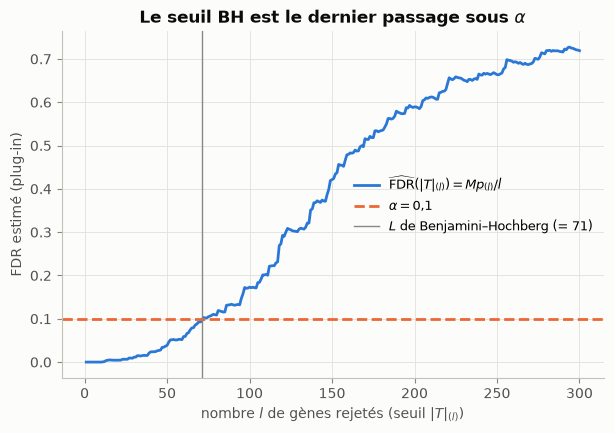

In [7]:
a = 0.1
L, _ = g18.benjamini_hochberg(ps, a)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(l, fdr_l, color=BLUE, label=r"$\widehat{\mathrm{FDR}}(|T|_{(l)}) = M p_{(l)}/l$")
ax.axhline(a, color=ORANGE, ls="--", label=r"$\alpha = 0{,}1$")
ax.axvline(L, color=GRAY, lw=1, label="$L$ de Benjamini–Hochberg (= %d)" % L)
ax.set_xlabel("nombre $l$ de gènes rejetés (seuil $|T|_{(l)}$)")
ax.set_ylabel("FDR estimé (plug-in)")
ax.set_title("Le seuil BH est le dernier passage sous $\\alpha$")
ax.legend()
plt.show()

La courbe n'est pas monotone : BH prend le **dernier** $l$ pour lequel elle est sous
$\alpha$ (et pas le premier passage au-dessus), conformément à la définition de $L$
comme un maximum.

> **À retenir.** Avec les p-valeurs de permutation mutualisées,
> $\widehat{\text{FDR}}(|T|_{(l)}) = Mp_{(l)}/l$ : la condition de BH
> $p_{(l)} < \alpha l/M$ s'écrit $\widehat{\text{FDR}} < \alpha$. BH est donc la règle
> « le seuil le plus bas dont le FDR plug-in reste sous $\alpha$ ».

## Exercice 18.18 : pFDR, erreur de type I et puissance

**Énoncé (reformulé).** À l'aide du résultat (18.53), montrer que

$$
\text{pFDR} = \frac{\pi_0\cdot\{\text{erreur de type I de }\Gamma\}}
{\pi_0\cdot\{\text{erreur de type I de }\Gamma\} + \pi_1\cdot\{\text{puissance de }\Gamma\}}
\qquad\text{(éq. (18.59), Storey 2003).}
$$

### Rappels : le modèle de mélange (18.51)–(18.53)

Chaque test $j$ a une variable cachée $Z_j \in \{0, 1\}$ ($Z_j = 0$ : $H_{0j}$ vraie),
avec $\Pr(Z_j = 0) = \pi_0$ et $\pi_1 = 1 - \pi_0$. La statistique suit $F_0$ si
$Z_j = 0$ et $F_1$ si $Z_j = 1$ ; les couples $(t_j, Z_j)$ sont i.i.d. On rejette quand
$t_j \in \Gamma$ (région de rejet). Le résultat (18.53) affirme
$\text{pFDR}(\Gamma) = \Pr(Z_j = 0 \mid t_j \in \Gamma)$ (démontré à l'exercice 18.20).

Par définition :

- erreur de type I de $\Gamma$ : $\Pr(t_j \in \Gamma \mid Z_j = 0)$ (rejeter à tort) ;
- puissance de $\Gamma$ : $\Pr(t_j \in \Gamma \mid Z_j = 1)$ (rejeter à raison).

### Solution

On applique la **formule de Bayes** à l'événement $\{t_j \in \Gamma\}$, puis la
**formule des probabilités totales** au dénominateur (partition $\{Z_j = 0\}$,
$\{Z_j = 1\}$) :

$$
\begin{aligned}
\text{pFDR}(\Gamma) &= \Pr(Z_j = 0 \mid t_j \in \Gamma)
  = \frac{\Pr(t_j \in \Gamma \mid Z_j = 0)\Pr(Z_j = 0)}{\Pr(t_j \in \Gamma)} \\
&= \frac{\pi_0\Pr(t_j \in \Gamma \mid Z_j = 0)}
   {\pi_0\Pr(t_j \in \Gamma \mid Z_j = 0) + \pi_1\Pr(t_j \in \Gamma \mid Z_j = 1)} \\
&= \frac{\pi_0\cdot\{\text{type I}\}}{\pi_0\cdot\{\text{type I}\} + \pi_1\cdot\{\text{puissance}\}} .
\end{aligned}
$$

> **Intuition.** Parmi les rejets, la part de « fausses découvertes » est la part du
> flux $\pi_0\times$(type I) dans le flux total de rejets. Une région très sévère réduit
> le type I, mais aussi la puissance : le pFDR baisse si le type I diminue plus vite.

### Vérification par simulation

Mélange $\pi_0 = 0{,}8$ de $F_0 = \mathcal N(0, 1)$ et $\pi_1 = 0{,}2$ de
$F_1 = \mathcal N(2{,}5, 1)$, $M = 500$ tests, régions $\Gamma_c = \{|t| > c\}$. On
compare la moyenne de $V/R$ sur les répétitions où $R > 0$ à la formule (18.59).

In [8]:
rng = np.random.RandomState(1)
pi0, mu1, M, n_rep = 0.8, 2.5, 500, 2000
cs = np.linspace(0.5, 4.0, 15)
Zs = rng.rand(n_rep, M) > pi0                          # True = non nulle
tt = rng.randn(n_rep, M) + mu1 * Zs
pfdr_sim = []
for c in cs:
    rej = np.abs(tt) > c
    R = rej.sum(axis=1)
    V = (rej & ~Zs).sum(axis=1)
    pfdr_sim.append(np.mean(V[R > 0] / R[R > 0]))
typeI = 2 * stats.norm.sf(cs)
power = stats.norm.sf(cs - mu1) + stats.norm.cdf(-cs - mu1)
pfdr_th = pi0 * typeI / (pi0 * typeI + (1 - pi0) * power)